In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

crash_summary_2019= pd.read_csv("CrashMap_data(2019).csv", low_memory=False)
print(crash_summary_2019.shape)
crash_summary_2019.head()


(116087, 9)


,Reportnumber,CircumstancesCode,DriverID,NonMotoristID,PassengerID,Vehicleid,CrashPoint,Latitude (generated),Longitude (generated)
0,ZW02290006,*,0d1727bb-8b69-4ddc-8d12-6adf4a133a31,NaN,NaN,5f2bd3ec-1391-43b9-bc55-23cfab80f2bf,Point,38.206701,-75.413587
1,ZW02290005,*,8ec13f47-040d-4f9d-87d1-e00ca74fa0c6,NaN,10bf0a24-2924-4b8a-8130-d786d63ed60e,3422fe76-83a8-4c2b-b04a-3332fd98b76a,Point,38.323769,-75.150877
2,ZW02290004,NaN,3206c9ac-43db-4b56-8170-a598c7c2b0f1,NaN,NaN,8b0a1d16-79ac-4347-a505-5a6fc4adc633,Point,38.362216,-75.289620
3,ZW02290002,*,65656fb4-bc3e-453d-abdf-bb3166470834,NaN,NaN,29aff242-a8eb-4318-a367-df04838347f0,Point,38.315970,-75.143174
4,ZW02280001,*,26f6fc5a-81aa-4d5e-bad2-48b1fca4eb88,NaN,NaN,b6888d32-66cb-4383-9d5a-0c17903b5416,Point,38.051597,-75.567602


In [ ]:
#combine all the datasets together

years= [2019,2020,2021,2022,2023]

data={}
for y in years:
    data[y]= pd.read_csv(f"CrashMap_REPORT_{y}.csv", low_memory=False)
    data[y]["Crashdate"]= pd.to_datetime(data[y]["Crashdate"], errors="coerce")
    print(y, data[y].shape,
          data[y]["Crashdate"].min().date(), "to", data[y]["Crashdate"].max().date(), 
          "| unique reports:", data[y]["Reportnumber"].nunique())

2019 (116087, 9) 2019-01-01 to 2019-12-31 | unique reports: 116087
2020 (95714, 9) 2020-01-01 to 2020-12-31 | unique reports: 95714
2021 (108969, 9) 2021-01-01 to 2021-12-31 | unique reports: 108969
2022 (108600, 9) 2022-01-01 to 2022-12-31 | unique reports: 108600
2023 (110472, 9) 2023-01-01 to 2023-12-31 | unique reports: 110472


In [5]:
#stack the datasets together

df=pd.concat(data.values(), ignore_index=True)

print(df.shape)
print(df["Reportnumber"].duplicated().sum())
df["year"]=df["Crashdate"].dt.year
print(df["year"].value_counts().sort_index())

df.to_csv("MD_crashes_2019_2023.csv", index=False)

(539842, 9)
0
year
2019    116087
2020     95714
2021    108969
2022    108600
2023    110472
Name: count, dtype: int64


In [6]:
print(df["UseData"].value_counts(dropna=False).head(10))
print(df["Reporttype"].value_counts(dropna=False))
print(df["CountyOfCrash"].value_counts(dropna=False))
print(df.isna().mean().round(3))
print(df[["Latitude", "Longitude"]].describe())

UseData
True    539842
Name: count, dtype: int64
Reporttype
Property Damage Crash    393470
Injury Crash             143596
Fatal Crash                2776
Name: count, dtype: int64
CountyOfCrash
Baltimore          100876
Prince George's     98172
Baltimore City      84181
Montgomery          60099
Anne Arundel        47896
Howard              18853
Frederick           16654
Harford             16063
Charles             14082
Washington          12393
Wicomico            10498
Carroll              9501
Cecil                8248
St. Mary's           8140
Worcester            6863
Calvert              5200
Queen Anne's         4043
Talbot               3851
Allegany             3714
Dorchester           2717
Caroline             2513
Garrett              2467
Somerset             1616
Kent                 1202
Name: count, dtype: int64
Reportnumber     0.0
AgencyCode       0.0
CountyOfCrash    0.0
Reporttype       0.0
UseData          0.0
Crashdate        0.0
CrashPoint       0.0
Latitud

In [11]:
#get rid of bad coordinates
in_md=df["Latitude"].between(37.9, 39.73) & df["Longitude"].between(-79.5, -75.0)
df.loc[~in_md & df["Latitude"].notna(), ["Reportnumber", "CountyOfCrash", "Latitude", "Longitude"]].head(20)

df=df.drop(columns=["UseData", "CrashPoint"])

df["Latitude"]= df["Latitude"].where(in_md)
df["Longitude"]=df["Longitude"].where(in_md)

In [16]:
df["Crashdate"]= pd.to_datetime(df["Crashdate"], errors="coerce")
df["year"]= df["Crashdate"].dt.year
df["month"]= df["Crashdate"].dt.month

type_map={
    "Property Damage Crash": "property_damage_crashes",
    "Injury Crash": "injury_crashes",
    "Fatal Crash": "fatal_crashes",
}

df["crash_type"]= df["Reporttype"].map(type_map)

monthly=(
    df.groupby(["CountyOfCrash", "year", "month", "crash_type"])
    .size().unstack("crash_type", fill_value=0).reset_index().rename(columns={"CountyOfCrash": "county"})
)

countries= monthly["county"].unique()
full= pd.MultiIndex.from_product([countries, range(2019,2024), range(1,13)], names=["county", "year", "month"])
monthly= (monthly.set_index(["county", "year", "month"]).reindex(full, fill_value=0).reset_index())

monthly["total_crashes"]=(monthly["property_damage_crashes"]+monthly["injury_crashes"]+monthly["fatal_crashes"])
monthly["injury_or_fatal_crashes"]= monthly["injury_crashes"]+monthly["fatal_crashes"]

monthly["year_month"]=pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
monthly["days_in_month"]= monthly["year_month"].dt.days_in_month
monthly["crashes_per_day"]=(monthly["total_crashes"]/monthly["days_in_month"]).round(2)

monthly.to_csv("md_crashes_by_county_month.csv", index=False)

In [17]:
print(monthly.shape)
print(monthly["total_crashes"].sum())
print(monthly["county"].nunique())
print(monthly.groupby("year")["total_crashes"].sum())

(1440, 11)
539842
24
year
2019    116087
2020     95714
2021    108969
2022    108600
2023    110472
Name: total_crashes, dtype: int64


In [18]:
monthly= monthly.sort_values(["county", "year", "month"]).reset_index(drop=True)
monthly.head(12)
print(monthly.dtypes)
print((monthly["total_crashes"]==0).sum())

crash_type
county                                str
year                                int32
month                               int32
fatal_crashes                       int64
injury_crashes                      int64
property_damage_crashes             int64
total_crashes                       int64
injury_or_fatal_crashes             int64
year_month                 datetime64[us]
days_in_month                       int32
crashes_per_day                   float64
dtype: object
0


In [21]:
print(sorted(monthly["county"].unique()))

['Allegany', 'Anne Arundel', 'Baltimore', 'Baltimore City', 'Calvert', 'Caroline', 'Carroll', 'Cecil', 'Charles', 'Dorchester', 'Frederick', 'Garrett', 'Harford', 'Howard', 'Kent', 'Montgomery', "Prince George's", "Queen Anne's", 'Somerset', "St. Mary's", 'Talbot', 'Washington', 'Wicomico', 'Worcester']


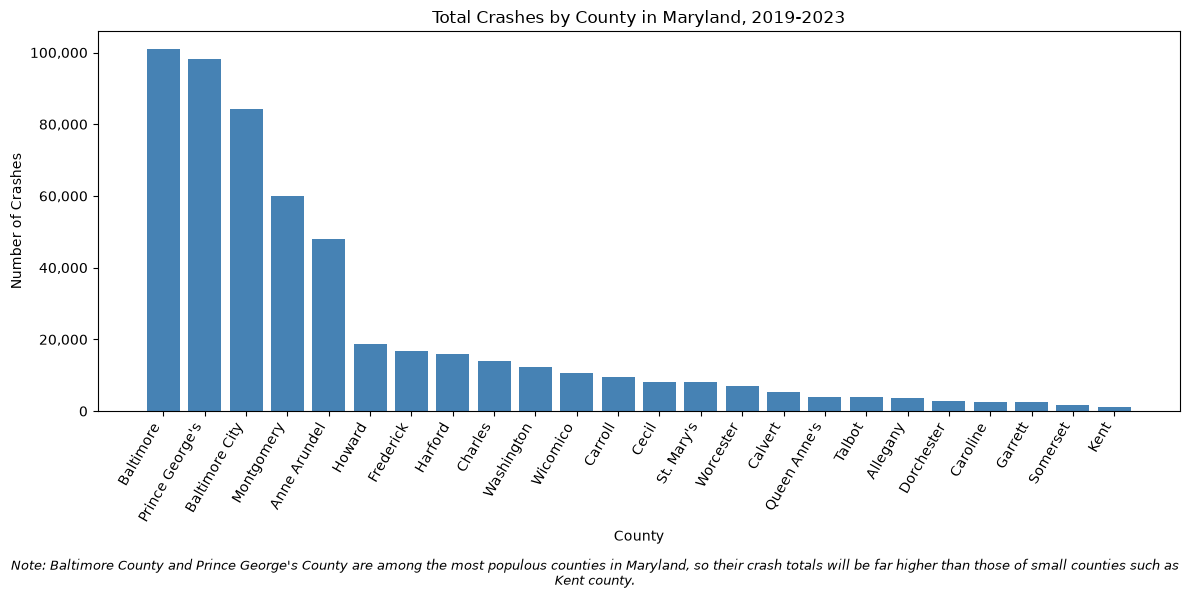

In [24]:
#graph

by_county= (monthly.groupby("county")["total_crashes"].sum().sort_values(ascending=False))

fig, ax=plt.subplots(figsize=(12,6))
ax.bar(by_county.index, by_county.values, color="Steelblue")

ax.set_title("Total Crashes by County in Maryland, 2019-2023")
ax.set_xlabel("County")
ax.set_ylabel("Number of Crashes")
ax.set_xticks(range(len(by_county)))
ax.set_xticklabels(by_county.index, rotation=60, ha="right")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _:f"{int(x):,}"))

note=("Note: Baltimore County and Prince George's County are among the most populous counties in Maryland, so their crash totals will be far higher than those of small counties such as Kent county.")
fig.text(0.5, 0.01, note, ha="center", va="bottom", fontsize=9, style="italic", wrap=True)

plt.tight_layout(rect=[0,0.06,1,1])
plt.savefig("crashes_by_county.png", dpi=200)
plt.show()

NameError: name 'np' is not defined

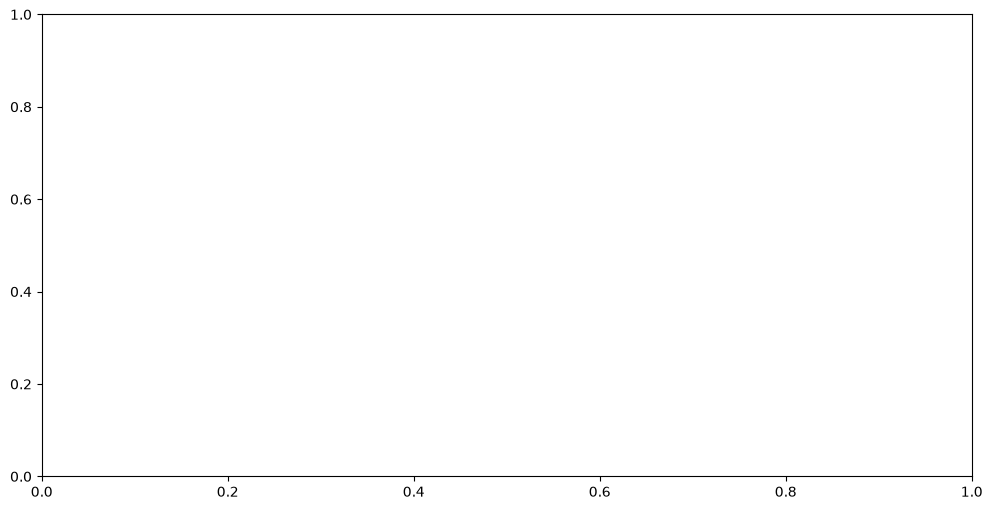

In [27]:
#Crash data by county for year range

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def county_monthly_chart(county, filename=None):
    d = monthly[monthly["county"] == county]
    pivot = d.pivot(index="month", columns="year", values="total_crashes")   # 12 rows x 5 years

    fig, ax = plt.subplots(figsize=(12, 6))
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(pivot.columns)))
    for color, yr in zip(colors, pivot.columns):
        ax.plot(pivot.index, pivot[yr], marker="o", label=str(yr), color=color)

    ax.set_title(f"{county} County: Crashes by Month, 2019-2023")
    ax.set_xlabel("Month")
    ax.set_ylabel("Number of Crashes")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend(title="Year")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

    plt.tight_layout()
    if filename is None:
        filename = f"monthly_crashes_{county.replace(' ', '_').replace(chr(39), '')}.png"
    plt.savefig(filename, dpi=200)
    plt.show()
    plt.close(fig)


for c in sorted(monthly["county"].unique()):
    county_monthly_chart(c)